In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LassoCV, Lasso
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
SEED = 42
sns.set_theme(style="whitegrid")

# Práctica 1: Regresión temporal del consumo de electrodomésticos
**Curso:** Inteligencia Artificial, semana 6, clase 6

**Objetivo:** comparar una RNA entrenada con todas las variables contra la misma RNA entrenada con subconjuntos seleccionados, usando solo datos de entrenamiento para seleccionar y respetando el orden temporal.

**Dataset:** Appliances Energy Prediction (UCI, CC BY 4.0).

**Estructura del notebook**

Las secciones siguen las actividades de la guía y se agrupan en cuatro bloques:

| Bloque | Actividades de la guía |
|---|---|
| Exploración y preparación de datos | 1-2 (descarga, orden y atributos temporales), 6 (partición temporal) y 3 (exploración, redundancia, `rv1` y `rv2`) |
| Selección de variables | 4 (técnicas de selección, estabilidad y subconjuntos candidatos) |
| Entrenamiento y validación de modelos | 5 (comparación con la misma arquitectura) |
| Evaluación final y conclusiones | Lista final y justificación, 7 (evaluación en prueba) y conclusión |

## Actividades 1 y 2. Descarga, orden cronológico y atributos temporales
Se descargan los datos, se ordenan por `date` y se transforma la fecha en atributos utilizables (`hour_sin`, `hour_cos`, `day_of_week`). La fecha no ingresa como texto a la red. Como esta copia del dataset trae la fecha sin espacio entre día y hora, se normaliza el formato antes de convertirla.

In [3]:
energy = fetch_ucirepo(id=374)
X_raw = energy.data.features.copy()
y_raw = energy.data.targets.squeeze().astype(float)

df = X_raw.copy()
df["Appliances"] = y_raw.to_numpy()
# Algunas versiones del dataset traen la fecha sin espacio ("2016-01-1117:00:00"); lo normalizo
df["date"] = pd.to_datetime(
    df["date"].astype(str).str.strip().str.replace(
        r"^(\d{4}-\d{2}-\d{2})\s*(\d{2}:\d{2}:\d{2})$", r"\1 \2", regex=True
    ),
    format="%Y-%m-%d %H:%M:%S"
)
df = df.sort_values("date").reset_index(drop=True)

# Atributos temporales básicos (la fecha NO entra como texto a la red)
df["hour_sin"] = np.sin(2 * np.pi * df["date"].dt.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["date"].dt.hour / 24)
df["day_of_week"] = df["date"].dt.dayofweek

fechas = df["date"].copy()          # la guardo solo para graficar
y = df.pop("Appliances")
X = df.drop(columns="date")

print(X.shape)
display(X.head())

(19735, 30)


,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour_sin,hour_cos,day_of_week
0,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,...,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,-0.965926,-0.258819,0
1,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,...,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,-0.965926,-0.258819,0
2,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,...,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,-0.965926,-0.258819,0
3,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,...,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390,-0.965926,-0.258819,0
4,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,...,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,-0.965926,-0.258819,0


### Descripción de las variables (Actividad 1)

Registros: 19735 | Rango: 2016-01-11 17:00:00 -> 2016-05-27 18:00:00
Valores nulos totales: 0
Fechas ordenadas: True


,count,mean,std,min,25%,50%,75%,max
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000e+00,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,2.160000e+01,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,3.965667e+01,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,2.000000e+01,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,4.050000e+01,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,2.210000e+01,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,3.853000e+01,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,2.066667e+01,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,3.840000e+01,42.156667,51.090000
T5,19735.0,19.592106,1.844623,15.330000,18.277500,1.939000e+01,20.619643,25.795000


count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

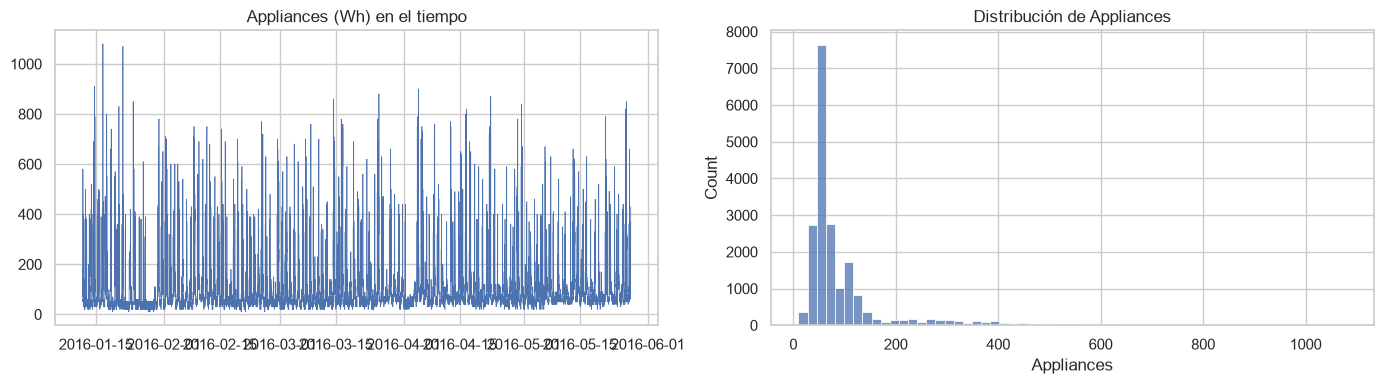

In [4]:
print("Registros:", len(X), "| Rango:", fechas.min(), "->", fechas.max())
print("Valores nulos totales:", int(X.isna().sum().sum()))
print("Fechas ordenadas:", fechas.is_monotonic_increasing)
display(X.describe().T)
display(y.describe())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(fechas, y, lw=0.5)
ax[0].set_title("Appliances (Wh) en el tiempo")
sns.histplot(y, bins=60, ax=ax[1])
ax[1].set_title("Distribución de Appliances")
plt.tight_layout(); plt.show()

## Actividad 6. Partición temporal: entrenamiento, validación y prueba
División cronológica 70 % / 15 % / 15 %, sin mezclar el orden. La prueba no se usa para seleccionar variables ni para ajustar la configuración.

In [5]:
n = len(X)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

X_train, y_train = X.iloc[:fin_train], y.iloc[:fin_train]
X_val, y_val = X.iloc[fin_train:fin_val], y.iloc[fin_train:fin_val]
X_test, y_test = X.iloc[fin_val:], y.iloc[fin_val:]

for nombre, f in [("Train", fechas.iloc[:fin_train]),
                  ("Val", fechas.iloc[fin_train:fin_val]),
                  ("Test", fechas.iloc[fin_val:])]:
    print(f"{nombre}: {f.min()} -> {f.max()} ({len(f)} registros)")

Train: 2016-01-11 17:00:00 -> 2016-04-16 15:10:00 (13814 registros)
Val: 2016-04-16 15:20:00 -> 2016-05-07 04:30:00 (2960 registros)
Test: 2016-05-07 04:40:00 -> 2016-05-27 18:00:00 (2961 registros)


## Actividad 3. Exploración: asociaciones, redundancia y comportamiento de `rv1` / `rv2`
A partir de acá todo el análisis para seleccionar variables usa únicamente `X_train` / `y_train`. Validación se usa para comparar candidatos y prueba queda reservada para el final.

### 3.1 Asociación con el objetivo (Appliances)

,pearson,spearman,abs_pearson
hour_sin,-0.250193,-0.431219,0.250193
hour_cos,-0.226071,-0.296517,0.226071
lights,0.225525,0.354237,0.225525
T2,0.149626,0.324589,0.149626
RH_out,-0.147125,-0.220085,0.147125
T3,0.121399,0.238514,0.121399
RH_8,-0.115910,-0.234535,0.115910
T6,0.108138,0.198538,0.108138
T_out,0.092864,0.173137,0.092864
RH_1,0.089316,0.072436,0.089316


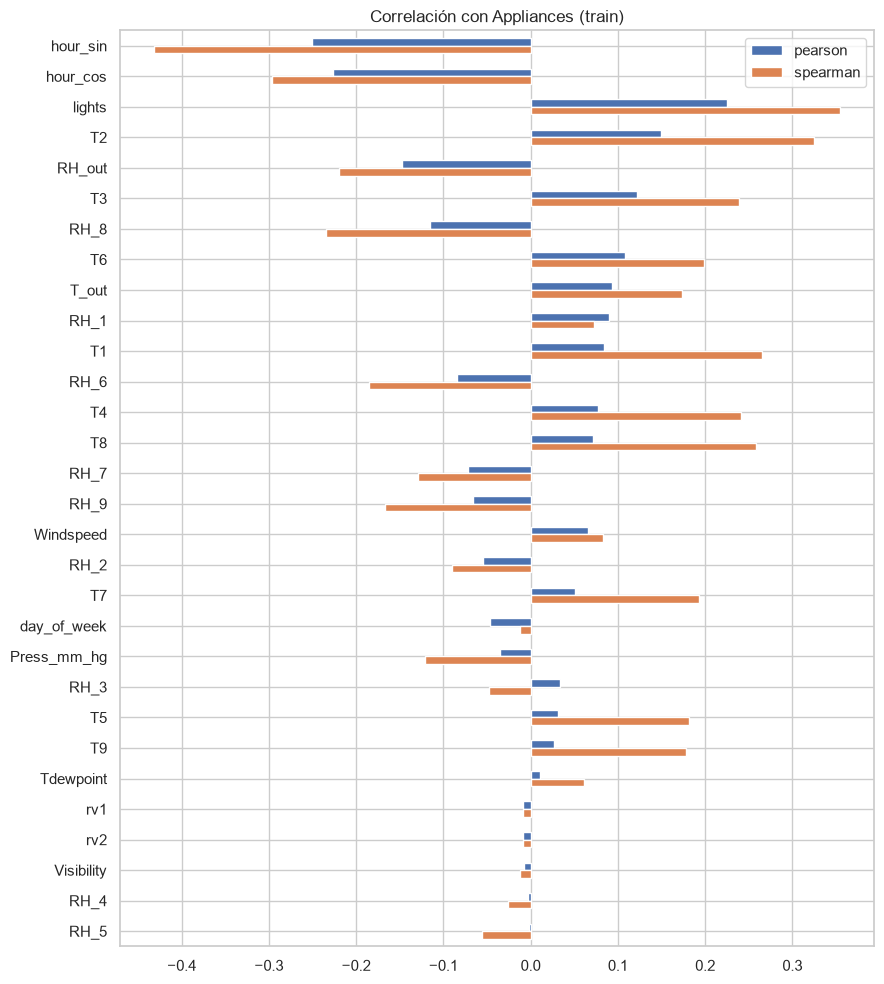

In [6]:
corr_obj = pd.DataFrame({
    "pearson": X_train.corrwith(y_train),
    "spearman": X_train.corrwith(y_train, method="spearman"),
})
corr_obj["abs_pearson"] = corr_obj["pearson"].abs()
corr_obj = corr_obj.sort_values("abs_pearson", ascending=False)
display(corr_obj)

corr_obj[["pearson", "spearman"]].plot.barh(figsize=(9, 10))
plt.title("Correlación con Appliances (train)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

### 3.2 Redundancia entre sensores

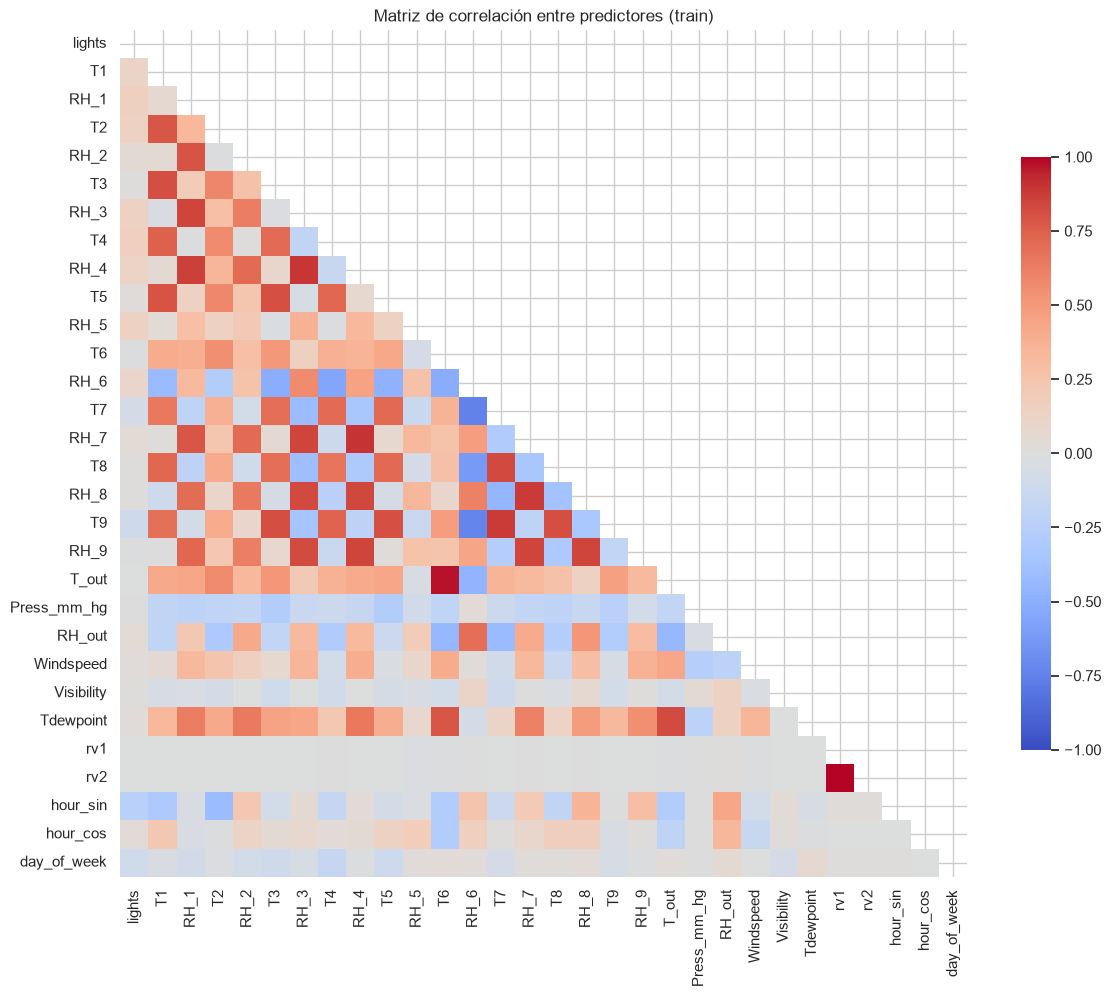

Pares con |r| > 0.90: 2


,var1,var2,corr
805,rv2,rv1,1.000000
581,T_out,T6,0.973869


In [7]:
corr = X_train.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.7})
plt.title("Matriz de correlación entre predictores (train)")
plt.show()

pares = (corr.where(~mask).stack().rename("corr").reset_index()
         .rename(columns={"level_0": "var1", "level_1": "var2"}))
pares = pares[pares["corr"].abs() > 0.90].sort_values("corr", key=abs, ascending=False)
print(f"Pares con |r| > 0.90: {len(pares)}")
display(pares)

### 3.3 Comportamiento de `rv1` y `rv2`

Correlación rv1 vs rv2: 1.0
Correlación rv1 vs Appliances: -0.0093
Correlación rv2 vs Appliances: -0.0093


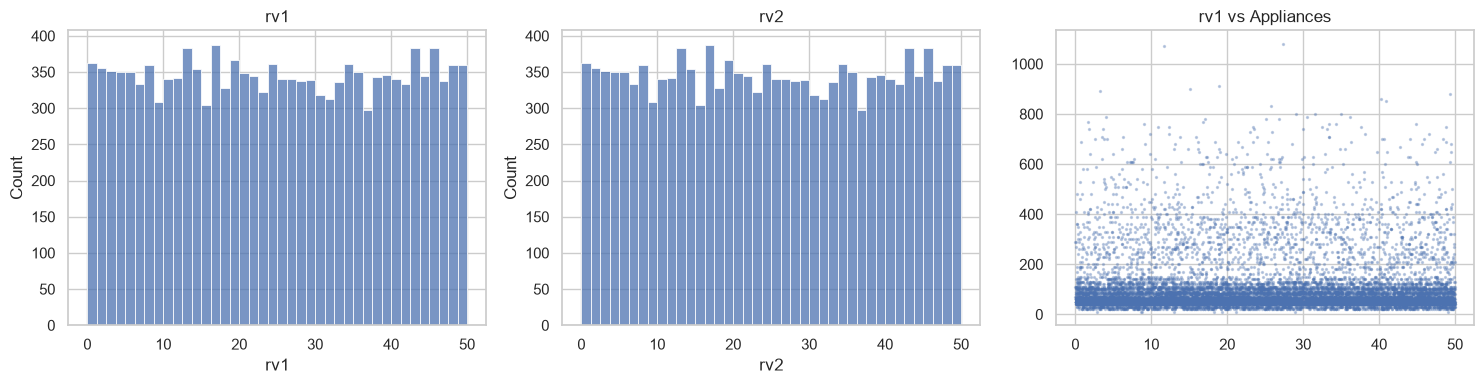

In [8]:
print("Correlación rv1 vs rv2:", round(X_train["rv1"].corr(X_train["rv2"]), 4))
print("Correlación rv1 vs Appliances:", round(X_train["rv1"].corr(y_train), 4))
print("Correlación rv2 vs Appliances:", round(X_train["rv2"].corr(y_train), 4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(X_train["rv1"], ax=ax[0], bins=40); ax[0].set_title("rv1")
sns.histplot(X_train["rv2"], ax=ax[1], bins=40); ax[1].set_title("rv2")
ax[2].scatter(X_train["rv1"], y_train, s=2, alpha=0.3)
ax[2].set_title("rv1 vs Appliances")
plt.tight_layout(); plt.show()

### 3.4 Observaciones de la exploración
- **Asociación con Appliances:** las variables con mayor correlación de Pearson son `hour_sin` (−0,25), `hour_cos` (−0,23) y `lights` (0,23). Todas las asociaciones lineales son débiles (|r| < 0,26). La correlación de Spearman es mayor (`hour_sin` −0,43, `lights` 0,35), lo que sugiere relaciones monótonas no lineales y un fuerte componente horario.
- **Redundancia:** solo dos pares superan |r| > 0,90: `rv1`–`rv2` (r = 1,00) y `T6`–`T_out` (r = 0,97). Las demás temperaturas y humedades están correlacionadas entre sí, pero por debajo de ese umbral.
- **rv1 y rv2:** son variables aleatorias de referencia y en esta copia del dataset son idénticas entre sí (r = 1,0000). Su correlación con el objetivo es −0,009 y su información mutua es 0, es decir, no aportan información y sirven como control de ruido.

## Actividad 4. Técnicas de selección de variables y subconjuntos candidatos
Se aplican cuatro técnicas, todas usando solo `train`:
1. **Información mutua** + filtro de redundancia por correlación.
2. **Regularización L1 (LassoCV)** con `TimeSeriesSplit`.
3. **Importancia por permutación** calculada en validación interna temporal (dentro de `train`).
4. Análisis de **estabilidad** de las selecciones a lo largo de ventanas temporales.

### 4.1 Información mutua

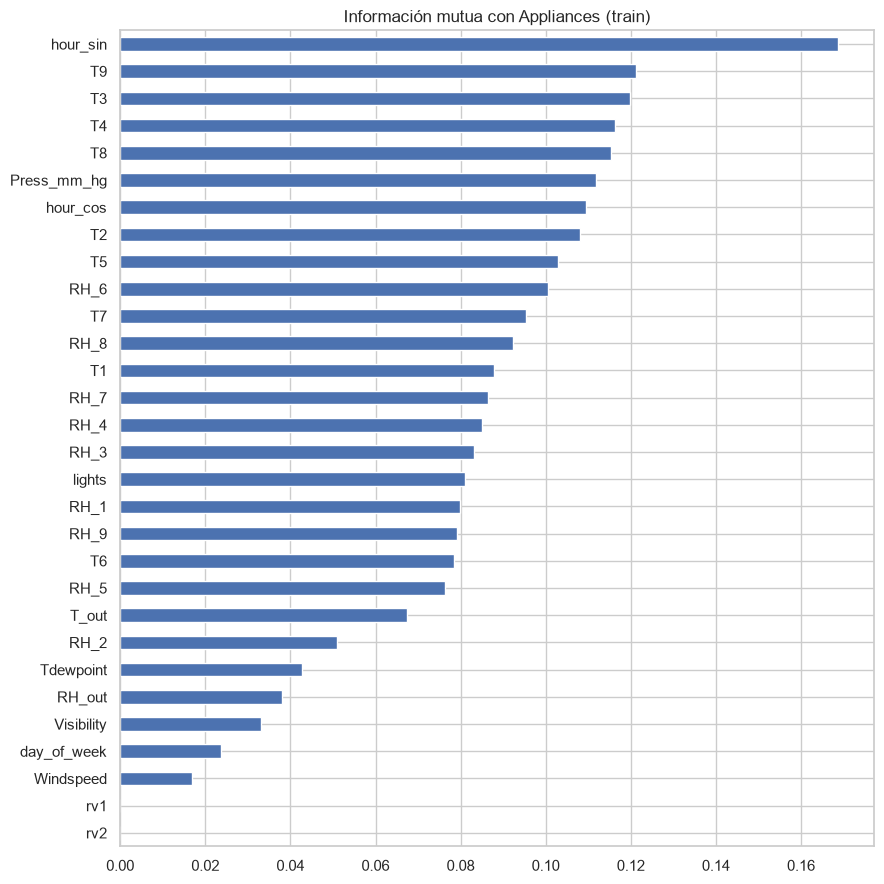

,MI
hour_sin,0.168716
T9,0.121168
T3,0.119882
T4,0.116300
T8,0.115228
Press_mm_hg,0.111869
hour_cos,0.109385
T2,0.108152
T5,0.102847
RH_6,0.100461


In [9]:
mi = pd.Series(
    mutual_info_regression(X_train, y_train, random_state=SEED),
    index=X_train.columns
).sort_values(ascending=False)

mi.plot.barh(figsize=(9, 9)); plt.gca().invert_yaxis()
plt.title("Información mutua con Appliances (train)")
plt.tight_layout(); plt.show()
display(mi.to_frame("MI"))

### 4.2 Importancia por permutación (validación temporal interna dentro de `train`)

fold 1 listo
fold 2 listo
fold 3 listo
fold 4 listo


,media,desvio
RH_2,19.914808,23.999700
hour_sin,12.872220,8.309484
hour_cos,7.188897,6.502841
RH_3,6.014882,5.360236
T6,3.006618,2.422208
RH_1,2.959263,2.119441
lights,2.104355,2.949640
RH_4,1.538446,4.157705
RH_7,1.389920,3.953157
Tdewpoint,1.043113,1.559643


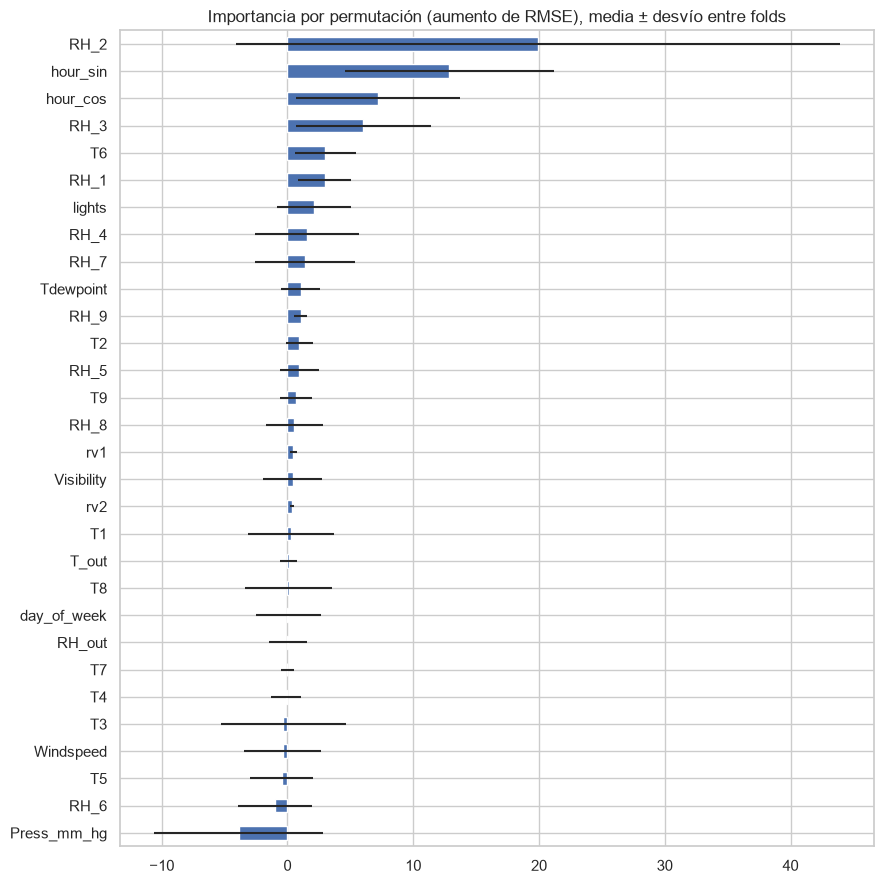

In [10]:
def crear_rna_reg(seed=SEED):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu",
                             max_iter=800, shuffle=False, random_state=seed))
    ])

tscv = TimeSeriesSplit(n_splits=4)
imp_folds = []
for i, (tr, te) in enumerate(tscv.split(X_train), 1):
    m = crear_rna_reg()
    m.fit(X_train.iloc[tr], y_train.iloc[tr])
    r = permutation_importance(
        m, X_train.iloc[te], y_train.iloc[te],
        scoring="neg_root_mean_squared_error",
        n_repeats=5, random_state=SEED, n_jobs=-1
    )
    imp_folds.append(pd.Series(r.importances_mean, index=X_train.columns, name=f"fold{i}"))
    print(f"fold {i} listo")

imp_df = pd.concat(imp_folds, axis=1)
imp_df["media"] = imp_df.mean(axis=1)
imp_df["desvio"] = imp_df.drop(columns="media").std(axis=1)
imp_df = imp_df.sort_values("media", ascending=False)
display(imp_df[["media", "desvio"]])

imp_df["media"].plot.barh(xerr=imp_df["desvio"], figsize=(9, 9)); plt.gca().invert_yaxis()
plt.title("Importancia por permutación (aumento de RMSE), media ± desvío entre folds")
plt.tight_layout(); plt.show()

### 4.3 Regularización L1 (LassoCV)

In [12]:
lasso_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", LassoCV(cv=TimeSeriesSplit(n_splits=5), random_state=SEED,
                      max_iter=50000))
])
lasso_pipe.fit(X_train, y_train)
lasso = lasso_pipe.named_steps["lasso"]
coef = pd.Series(lasso.coef_, index=X_train.columns)
print("alpha elegido:", lasso.alpha_)
display(coef[coef != 0].sort_values(key=abs, ascending=False).to_frame("coef"))
print("Variables eliminadas por L1:", list(coef[coef == 0].index))

alpha elegido: 1.8860319324969865


,coef
hour_cos,-24.160308
T3,19.054020
hour_sin,-18.467724
lights,17.229576
RH_1,7.817973
RH_7,-7.682037
RH_3,4.067376
T9,-3.713820
RH_2,-3.422016
T4,-3.316994


Variables eliminadas por L1: ['T1', 'T2', 'RH_4', 'RH_5', 'RH_6', 'T7', 'RH_8', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'day_of_week']


### 4.4 Estabilidad de la selección entre ventanas temporales

,MI_top10,Lasso_no_cero
T3,5,3
RH_7,5,3
Press_mm_hg,5,3
T2,5,0
T9,4,3
T8,4,1
hour_sin,3,5
T4,3,3
T7,3,2
lights,2,5


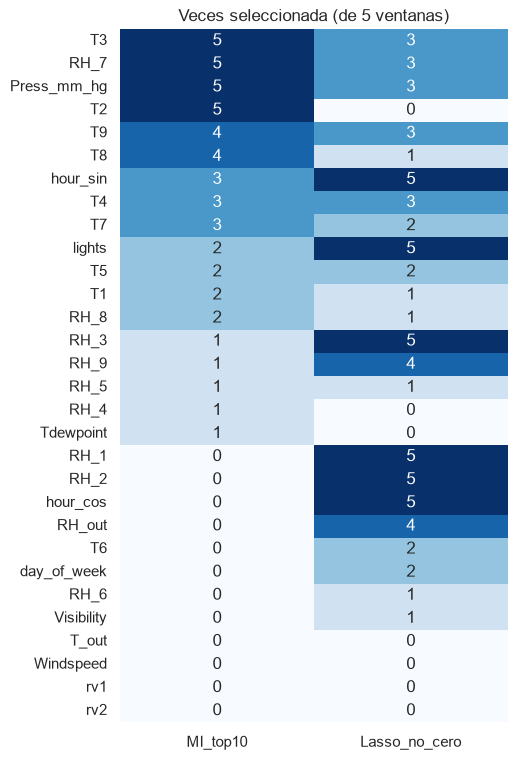

In [13]:
K = 10
tscv_est = TimeSeriesSplit(n_splits=5)
freq = pd.DataFrame(0, index=X_train.columns, columns=["MI_top10", "Lasso_no_cero"])

for tr, _ in tscv_est.split(X_train):
    Xt, yt = X_train.iloc[tr], y_train.iloc[tr]
    mi_f = pd.Series(mutual_info_regression(Xt, yt, random_state=SEED), index=X_train.columns)
    freq.loc[mi_f.nlargest(K).index, "MI_top10"] += 1

    sc = StandardScaler().fit(Xt)
    l = Lasso(alpha=lasso.alpha_, max_iter=50000).fit(sc.transform(Xt), yt)
    freq.loc[X_train.columns[l.coef_ != 0], "Lasso_no_cero"] += 1

freq = freq.sort_values(["MI_top10", "Lasso_no_cero"], ascending=False)
display(freq)
plt.figure(figsize=(5, 9))
sns.heatmap(freq, annot=True, cmap="Blues", cbar=False)
plt.title("Veces seleccionada (de 5 ventanas)")
plt.show()

### 4.5 Subconjuntos candidatos

In [14]:
def filtrar_redundancia(orden, corr_abs, umbral=0.90):
    elegidas = []
    for f in orden:
        if all(corr_abs.loc[f, g] < umbral for g in elegidas):
            elegidas.append(f)
    return elegidas

corr_abs = X_train.corr().abs()

# A: Información mutua + filtro de redundancia (top 10)
subset_A = filtrar_redundancia(list(mi.index), corr_abs, 0.90)[:10]

# B: Lasso (coeficientes distintos de cero)
subset_B = list(coef[coef != 0].index)

# C: Permutación (importancia media > 0), sin redundancia, top 12
cand_C = list(imp_df[imp_df["media"] > 0].index)
subset_C = filtrar_redundancia(cand_C, corr_abs, 0.90)[:12]

candidatos = {
    "Todas": list(X.columns),
    "A_MI_sin_redundancia": subset_A,
    "B_Lasso": subset_B,
    "C_Permutacion": subset_C,
}
for k, v in candidatos.items():
    print(f"{k} ({len(v)}): {v}\n")

Todas (30): ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour_sin', 'hour_cos', 'day_of_week']

A_MI_sin_redundancia (10): ['hour_sin', 'T9', 'T3', 'T4', 'T8', 'Press_mm_hg', 'hour_cos', 'T2', 'T5', 'RH_6']

B_Lasso (15): ['lights', 'RH_1', 'RH_2', 'T3', 'RH_3', 'T4', 'T5', 'T6', 'RH_7', 'T8', 'T9', 'RH_9', 'T_out', 'hour_sin', 'hour_cos']

C_Permutacion (12): ['RH_2', 'hour_sin', 'hour_cos', 'RH_3', 'T6', 'RH_1', 'lights', 'RH_4', 'RH_7', 'Tdewpoint', 'RH_9', 'T2']



## Actividad 5. Comparación con la misma arquitectura
Cambia **únicamente** el conjunto de variables. Arquitectura (64, 32), semilla 42, escalado, partición y métricas son idénticos.

### 5.1 Métricas en validación: todas las variables vs. subconjuntos

In [15]:
def metricas_reg(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

filas = {}
for nombre, feats in candidatos.items():
    modelo = crear_rna_reg()
    modelo.fit(X_train[feats], y_train)
    met = metricas_reg(y_val, modelo.predict(X_val[feats]))
    met["n_vars"] = len(feats)
    filas[nombre] = met

res_val = pd.DataFrame(filas).T.sort_values("RMSE")
display(res_val.round(3))

,MAE,RMSE,R2,n_vars
C_Permutacion,60.362,101.345,-0.207,12.0
A_MI_sin_redundancia,65.486,102.770,-0.241,10.0
Todas,60.759,104.607,-0.286,30.0
B_Lasso,74.231,112.047,-0.476,15.0


### 5.2 Línea base de referencia
Predictor que devuelve siempre la media de entrenamiento. Se calcula solo en validación y sirve para interpretar el R².

In [ ]:
# Línea base: predecir siempre la media de train (solo validación)
from sklearn.dummy import DummyRegressor
base = DummyRegressor(strategy="mean").fit(X_train, y_train)
res_base = pd.DataFrame({"Base (media)": metricas_reg(y_val, base.predict(X_val))}).T
display(res_base.round(3))

### 5.3 Robustez frente a la semilla (análisis complementario)

In [16]:
# La comparación principal usa semilla 42. Esto solo mide cuánto varía por inicialización.
semillas = [0, 1, 2, 3, 4]
robustez = {}
for nombre, feats in candidatos.items():
    rmses = []
    for s in semillas:
        m = crear_rna_reg(seed=s).fit(X_train[feats], y_train)
        rmses.append(np.sqrt(mean_squared_error(y_val, m.predict(X_val[feats]))))
    robustez[nombre] = {"RMSE_medio": np.mean(rmses), "RMSE_desvio": np.std(rmses)}
display(pd.DataFrame(robustez).T.round(3))

,RMSE_medio,RMSE_desvio
Todas,109.113,4.150
A_MI_sin_redundancia,95.964,2.499
B_Lasso,105.657,6.745
C_Permutacion,97.181,8.051


### 5.4 Elección final y configuración congelada

In [17]:
# Criterio sugerido: mejor RMSE de validación entre los subconjuntos (no "Todas").
# Podés cambiar el nombre a mano si priorizás parsimonia/estabilidad.
nombre_final = res_val.drop(index="Todas").sort_values("RMSE").index[0]
selected_features = candidatos[nombre_final]
print("Subconjunto final:", nombre_final)
print(f"{len(selected_features)} variables:", selected_features)

Subconjunto final: C_Permutacion
12 variables: ['RH_2', 'hour_sin', 'hour_cos', 'RH_3', 'T6', 'RH_1', 'lights', 'RH_4', 'RH_7', 'Tdewpoint', 'RH_9', 'T2']


## Lista final de variables y justificación
- **Subconjunto elegido:** C_Permutacion (12 variables): `RH_2`, `hour_sin`, `hour_cos`, `RH_3`, `T6`, `RH_1`, `lights`, `RH_4`, `RH_7`, `Tdewpoint`, `RH_9`, `T2`. Se eligió por tener el menor RMSE de validación entre los subconjuntos candidatos.
- **Desempeño en validación:** frente a las 30 variables (MAE 60,76, RMSE 104,61, R² −0,286), el subconjunto obtuvo MAE 60,36, RMSE 101,35 y R² −0,207. La mejora es pequeña y queda dentro de la variabilidad entre semillas (desvío del RMSE entre 4 y 8), por lo que en validación no se puede afirmar que sea una diferencia significativa.
- **Estabilidad:** 7 de las 12 variables (`RH_1`, `RH_2`, `RH_3`, `hour_sin`, `hour_cos`, `lights` y `RH_9`) fueron seleccionadas por Lasso en al menos 4 de 5 ventanas temporales. `RH_4`, `Tdewpoint` y `T2` tienen soporte débil. La importancia por permutación presenta desvíos altos entre folds (por ejemplo `RH_2`: 19,9 ± 24,0), así que su ranking es ruidoso.
- **Redundancia:** se aplicó un filtro de |r| < 0,90, que elimina el par `T6`–`T_out`. Se conservó `T6`.
- **rv1 / rv2:** quedaron fuera. Son idénticas entre sí, tienen información mutua 0 y correlación casi nula con el objetivo. Que la permutación les asigne importancia positiva pequeña (0,37 a 0,47) muestra el ruido de ese método.
- **Posibles fugas de información:** el escalado se ajusta dentro del `Pipeline` solo con entrenamiento, la selección usó únicamente entrenamiento (con validación temporal interna) y la prueba no intervino en ninguna decisión. Además, las variables meteorológicas externas son contemporáneas al consumo; en un uso real habría que usar pronósticos.
- **Nota de procedimiento:** en el análisis de robustez entre semillas, A_MI_sin_redundancia obtuvo un RMSE medio algo menor (95,96 vs 97,18). Se mantuvo C_Permutacion porque el criterio de elección (menor RMSE de validación con semilla 42) se fijó antes de mirar la prueba.

## Actividad 7. Evaluación final en prueba (una sola vez)
Se reentrenan ambos modelos con la configuración congelada y se evalúan en prueba con MAE, RMSE y R², junto a las métricas de validación para comparar.

In [18]:
modelo_todas = crear_rna_reg().fit(X_train[candidatos["Todas"]], y_train)
modelo_sel = crear_rna_reg().fit(X_train[selected_features], y_train)

pred_test_todas = modelo_todas.predict(X_test[candidatos["Todas"]])
pred_test_sel = modelo_sel.predict(X_test[selected_features])

res_test = pd.DataFrame({
    "Todas": metricas_reg(y_test, pred_test_todas),
    f"Seleccion ({nombre_final})": metricas_reg(y_test, pred_test_sel),
}).T
res_test["n_vars"] = [len(candidatos["Todas"]), len(selected_features)]
display(res_test.round(3))

res_val_final = res_val.loc[["Todas", nombre_final]].copy()
print("\nMétricas de validación (para comparar):")
display(res_val_final.round(3))

,MAE,RMSE,R2,n_vars
Todas,171.311,226.167,-5.194,30
Seleccion (C_Permutacion),92.137,129.326,-1.025,12



Métricas de validación (para comparar):


,MAE,RMSE,R2,n_vars
Todas,60.759,104.607,-0.286,30.0
C_Permutacion,60.362,101.345,-0.207,12.0


### Real vs. predicho en prueba

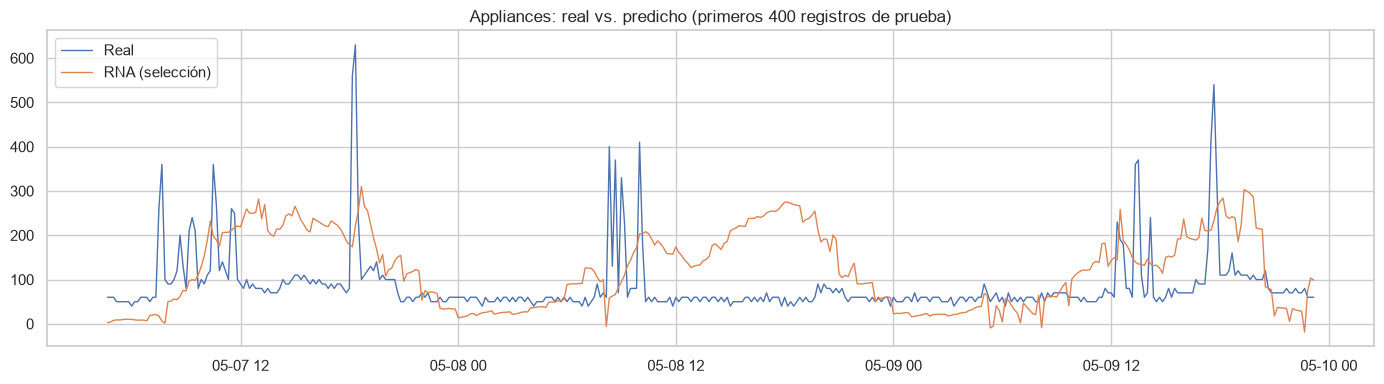

In [19]:
fig, ax = plt.subplots(figsize=(14, 4))
idx = fechas.iloc[fin_val:].iloc[:400]
ax.plot(idx, y_test.iloc[:400].values, label="Real", lw=1)
ax.plot(idx, pred_test_sel[:400], label="RNA (selección)", lw=1)
ax.set_title("Appliances: real vs. predicho (primeros 400 registros de prueba)")
ax.legend(); plt.tight_layout(); plt.show()

## Conclusión
En prueba, la RNA con las 12 variables seleccionadas mejoró claramente a la que usa las 30 (RMSE 129,3 vs 226,2; MAE 92,1 vs 171,3; R² −1,03 vs −5,19). Aun así, el R² negativo en validación y en prueba indica que el modelo no supera a un predictor que siempre devuelve la media, por lo que su desempeño absoluto es insuficiente. Entre las posibles causas están el ruido del consumo, la forma asimétrica del objetivo y el cambio de condiciones entre el período de entrenamiento (enero a abril) y el de prueba (mayo). La mejora grande en prueba contrasta con la diferencia mínima en validación; una hipótesis (no verificada en este trabajo) es que la selección aportó sobre todo robustez ante ese cambio de período, al dejar afuera la mayoría de las variables climáticas externas (`Press_mm_hg`, `T_out`, `Windspeed`, `Visibility`, `RH_out`), y no precisión en el período de validación. La selección reduce el modelo de 30 a 12 variables.